# Task 4: NLP Sentiment Classification on Movie Reviews (TF-IDF)
Pipeline: load reviews, clean and tokenize (lowercase, stopword removal, lemmatization), TF-IDF features, Multinomial Naive Bayes and Logistic Regression, then a `predict_sentiment()` helper for custom text.

## 1. Load the dataset
We use the NLTK `movie_reviews` corpus: 2,000 labeled movie reviews (1,000 positive and 1,000 negative). NLTK downloads it automatically.

In [1]:
import re, nltk
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from nltk.corpus import movie_reviews, stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score

for pkg in ['movie_reviews', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(pkg, quiet=True)
sns.set_theme(style='whitegrid')

records = [(movie_reviews.raw(fid), cat) for cat in movie_reviews.categories() for fid in movie_reviews.fileids(cat)]
df = pd.DataFrame(records, columns=['review', 'label'])
df['sentiment'] = (df['label'] == 'pos').astype(int)   # 1 = positive, 0 = negative
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
print(df.shape)
df.head()

(2000, 3)


,review,label,sentiment
0,the verdict : spine-chilling drama from horror...,pos,1
1,""" the 44 caliber killer has struck again . "" ...",neg,0
2,in the company of men made a splash at the sun...,pos,1
3,"in the year 2029 , captain leo davidson ( mark...",neg,0
4,[note that followups are directed to rec . art...,pos,1


## 2. Quick exploration

label
pos    1000
neg    1000
Name: count, dtype: int64


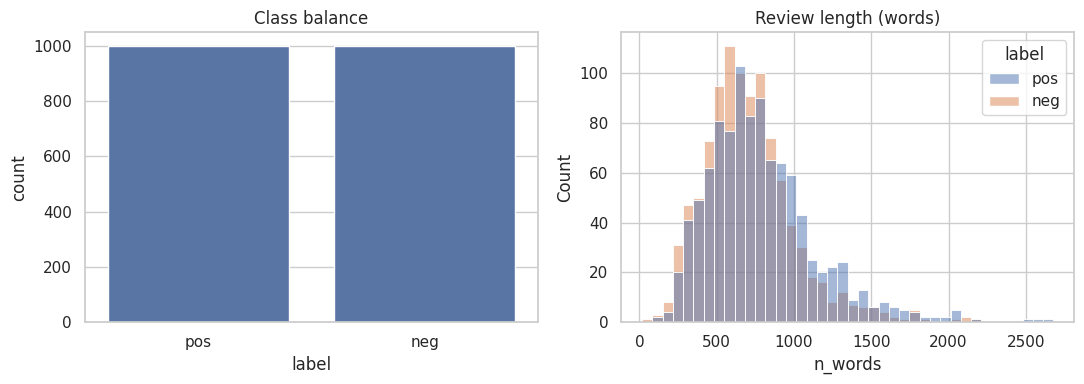

In [2]:
print(df['label'].value_counts())
df['n_words'] = df['review'].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.countplot(data=df, x='label', ax=axes[0]); axes[0].set_title('Class balance')
sns.histplot(data=df, x='n_words', hue='label', bins=40, ax=axes[1]); axes[1].set_title('Review length (words)')
plt.tight_layout(); plt.show()

## 3. Text preprocessing
Steps: remove HTML tags, lowercase, keep letters only, tokenize, remove stopwords, lemmatize.

Note: negation words (`not`, `no`, `nor`, `never`) are **kept** out of the stopword list, because removing them would turn "not good" into "good" and hurt sentiment accuracy.

In [3]:
lemmatizer = WordNetLemmatizer()
negations = {'not', 'no', 'nor', 'never'}
stop_words = set(stopwords.words('english')) - negations

def clean_text(text):
    text = re.sub(r'<[^>]+>', ' ', text)            # remove HTML tags
    text = text.lower()                              # lowercase
    text = re.sub(r"n't\b", ' not', text)            # don't -> do not
    text = re.sub(r'[^a-z\s]', ' ', text)            # remove punctuation, digits
    tokens = text.split()                            # tokenize
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]   # stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]                   # lemmatize
    return ' '.join(tokens)

sample = df['review'].iloc[0]
print('BEFORE:', sample[:300], '...\n')
print('AFTER :', clean_text(sample)[:300], '...')

BEFORE: the verdict : spine-chilling drama from horror maestro stephen king , featuring an outstanding , oscar-winning performance from kathy bates . 
geez , french and saunders had a field day when they set to work on parodying this ! 
sorry , non-british readers may not be familiar with french and saunder ...

AFTER : verdict spine chilling drama horror maestro stephen king featuring outstanding oscar winning performance kathy bates geez french saunders field day set work parodying sorry non british reader may not familiar french saunders apology pair british comedienne jennifer saunders later went become edina m ...


In [4]:
df['clean'] = df['review'].apply(clean_text)
df[['clean', 'sentiment']].head()

,clean,sentiment
0,verdict spine chilling drama horror maestro st...,1
1,caliber killer struck starring john leguizamo ...,0
2,company men made splash sundance film festival...,1
3,year captain leo davidson mark wahlberg boogie...,0
4,note followup directed rec art movie current f...,1


## 4. Train/test split and TF-IDF features
The vectorizer is fit on the training text only (no leakage).

In [5]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df['clean'], df['sentiment'], test_size=0.2, random_state=42, stratify=df['sentiment'])

tfidf = TfidfVectorizer(max_features=5000)
X_train = tfidf.fit_transform(X_train_txt)
X_test = tfidf.transform(X_test_txt)
print('TF-IDF matrix:', X_train.shape, '| vocabulary size:', len(tfidf.vocabulary_))

TF-IDF matrix: (1600, 5000) | vocabulary size: 5000


## 5. Train Multinomial Naive Bayes and Logistic Regression

In [6]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
}
preds, rows = {}, []
for name, m in models.items():
    m.fit(X_train, y_train)
    preds[name] = m.predict(X_test)
    print(f'===== {name} =====')
    print(classification_report(y_test, preds[name], target_names=['negative', 'positive']))
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, preds[name]),
                 'Precision': precision_score(y_test, preds[name]),
                 'Recall': recall_score(y_test, preds[name]),
                 'F1-score': f1_score(y_test, preds[name])})
results = pd.DataFrame(rows).set_index('Model').round(4)
display(results)

===== Multinomial Naive Bayes =====
              precision    recall  f1-score   support

    negative       0.76      0.89      0.82       200
    positive       0.86      0.72      0.78       200

    accuracy                           0.80       400
   macro avg       0.81      0.80      0.80       400
weighted avg       0.81      0.80      0.80       400

===== Logistic Regression =====
              precision    recall  f1-score   support

    negative       0.85      0.86      0.86       200
    positive       0.86      0.85      0.85       200

    accuracy                           0.85       400
   macro avg       0.86      0.85      0.85       400
weighted avg       0.86      0.85      0.85       400



,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial Naive Bayes,0.8025,0.8623,0.72,0.7847
Logistic Regression,0.8550,0.8586,0.85,0.8543


## 6. Accuracy benchmark and confusion matrices

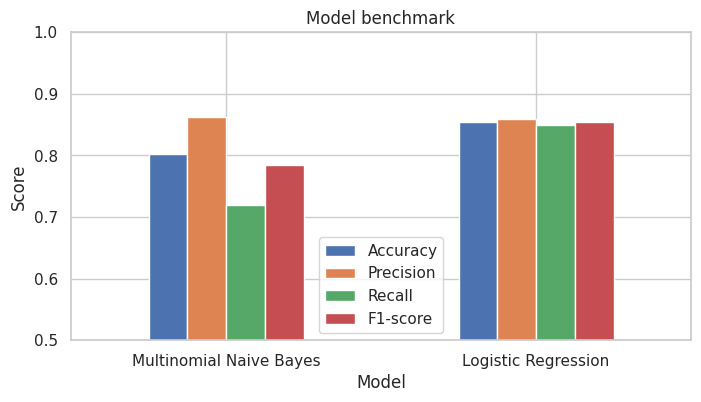

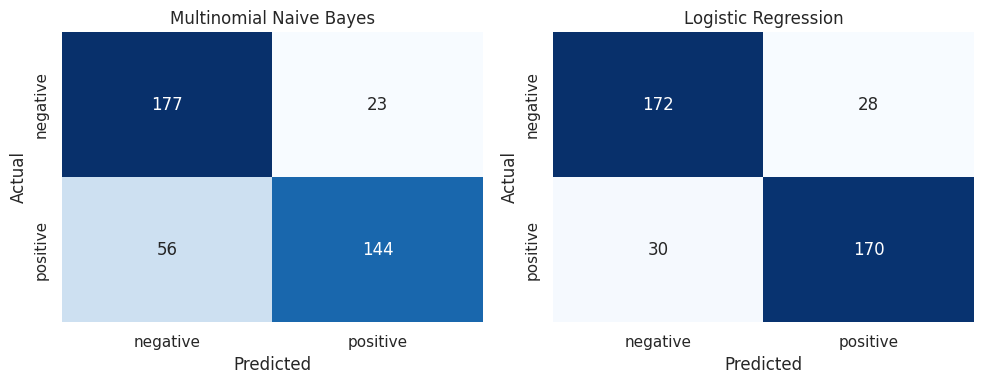

In [7]:
results.plot(kind='bar', figsize=(8,4), ylim=(0.5, 1.0), rot=0)
plt.title('Model benchmark'); plt.ylabel('Score'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10,4))
for ax, (name, p) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'], ax=ax)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 7. Most influential words (Logistic Regression)

In [8]:
lr = models['Logistic Regression']
words = np.array(tfidf.get_feature_names_out())
order = np.argsort(lr.coef_[0])
top = pd.DataFrame({'Most negative': words[order[:15]], 'Most positive': words[order[::-1][:15]]})
display(top)

,Most negative,Most positive
0,bad,life
1,plot,well
2,worst,great
3,no,also
4,boring,truman
5,not,war
6,supposed,world
7,stupid,performance
8,nothing,excellent
9,poor,fun


## 8. `predict_sentiment()`: test your own text

In [9]:
def predict_sentiment(text, model_name='Logistic Regression'):
    """Return the predicted sentiment and confidence for a raw review string."""
    model = models[model_name]
    vec = tfidf.transform([clean_text(text)])
    proba = model.predict_proba(vec)[0]
    label = 'Positive' if proba[1] >= 0.5 else 'Negative'
    return label, round(float(max(proba)), 3)

tests = [
    'This movie was absolutely fantastic, I loved every minute of it!',
    'Terrible plot, awful acting, a complete waste of time.',
    'The film was not good at all.',
    'A brilliant and moving story with wonderful performances.',
    'I was bored and the ending made no sense.',
]
for t in tests:
    for name in models:
        print(f'{name:25s} -> {predict_sentiment(t, name)}  | {t}')
    print()

Multinomial Naive Bayes   -> ('Positive', 0.58)  | This movie was absolutely fantastic, I loved every minute of it!
Logistic Regression       -> ('Positive', 0.531)  | This movie was absolutely fantastic, I loved every minute of it!

Multinomial Naive Bayes   -> ('Negative', 0.868)  | Terrible plot, awful acting, a complete waste of time.
Logistic Regression       -> ('Negative', 0.873)  | Terrible plot, awful acting, a complete waste of time.

Multinomial Naive Bayes   -> ('Negative', 0.517)  | The film was not good at all.
Logistic Regression       -> ('Positive', 0.524)  | The film was not good at all.

Multinomial Naive Bayes   -> ('Positive', 0.746)  | A brilliant and moving story with wonderful performances.
Logistic Regression       -> ('Positive', 0.819)  | A brilliant and moving story with wonderful performances.

Multinomial Naive Bayes   -> ('Negative', 0.543)  | I was bored and the ending made no sense.
Logistic Regression       -> ('Positive', 0.503)  | I was bored and the